<a href="https://colab.research.google.com/github/programadorarocio/practica_PNL/blob/main/TP2_NLP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Trabajo Práctico N°2 - Procesamiento del Lenguaje Natural - TUIA 2026

### Información Académica
- **Carrera:** Tecnicatura Universitaria en Inteligencia Artificial
- **Cátedra:** Procesamiento del Lenguaje Natural
- **Año:** 2026

---

### Integrantes del Grupo
1. **Martín Facundo Lapolla L-3372/3** - [Email: martinfacundolapolla@gmail.com / Usuario de GitHub: martinfl95]
2. **Nicolás Daniel Calabozo C-7551/5** - [Email: nicocalabozo@gmail.com / Usuario de GitHub: NicolasCalabozo]
3. **Jonatan Gallardo G-5970/6** - [Email: jonathannahtanoj8@gmail.com / Usuario de GitHub: jonatan-gallardo]
4. **Rocío Quispe Q-0484/7** - [Email: rociopq4@gmail.com / Usuario de GitHub: programadorarocio ]
5. **Miranda Pilar Onega O-1779/5** - [Email: mirandaonega@gmail.com / Usuario de GitHub: mirandaonega ]

### Módulos e Importaciones

In [ ]:
!pip install --upgrade gensim --quiet

In [ ]:
!pip install sentence-transformers psycopg2-binary pgvector --quiet

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import random
import re
from collections import Counter
import unicodedata

from sklearn.metrics.pairwise import cosine_similarity

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')
stop_words = set(stopwords.words('spanish'))

from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.decomposition import PCA

import gensim
from gensim.models import KeyedVectors, Word2Vec

from sentence_transformers import SentenceTransformer

import psycopg2
from pgvector.psycopg2 import register_vector
import numpy as np
import pandas as pd

from sklearn.decomposition import PCA

from google.colab import userdata
from google.colab import files

from IPython.display import HTML, display, JSON

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [ ]:
#Entorno:
local = False
if not local:
  !gdown 1pW6OrkBdy6rbns0q7dSzIER6fJEfVeD4
  !gdown 1V8hNcnGEyrz0c_dA-v0_5sg31bNgy75r
  !gdown 1sXC5N4cgV9dSODde27Df_DVF4EooV5Tn
  data = pd.read_csv('libros.csv')
  DB_URI = userdata.get('CONNECTION_URL')
else:
  data = pd.read_csv('./data/libros.csv')

Downloading...
From: https://drive.google.com/uc?id=1pW6OrkBdy6rbns0q7dSzIER6fJEfVeD4
To: /content/libros.csv
100% 182k/182k [00:00<00:00, 32.5MB/s]
Downloading...
From (original): https://drive.google.com/uc?id=1V8hNcnGEyrz0c_dA-v0_5sg31bNgy75r
From (redirected): https://drive.google.com/uc?id=1V8hNcnGEyrz0c_dA-v0_5sg31bNgy75r&confirm=t&uuid=95ad101b-d7bc-4948-af69-421cf9ccfef7
To: /content/SBW-vectors-300-min5.bin.gz
100% 1.12G/1.12G [00:21<00:00, 52.2MB/s]
Downloading...
From: https://drive.google.com/uc?id=1sXC5N4cgV9dSODde27Df_DVF4EooV5Tn
To: /content/queries.json
100% 2.19k/2.19k [00:00<00:00, 8.76MB/s]


### 0. Introducción

El presente Trabajo Práctico tiene como objetivo principal diseñar, implementar y evaluar empíricamente un motor de búsqueda y sistema de recomendación de libros, capaz de superar estas limitaciones mediante la aplicación de técnicas modernas de Procesamiento de Lenguaje Natural

Se contrastaron tres enfoques distintos para la recuperación de documentos. Se implementó TF-IDF como línea de base para la búsqueda léxica exacta; se entrenó un modelo propio de Word2Vec para explorar la creación de representaciones densas (vectores) a partir del corpus; y se integró SBERT (Sentence-BERT), un modelo basado en Transformers, para capturar la semántica profunda y el contexto.

La lógica de similitud se trasladó a un entorno de base de datos utilizando PostgreSQL junto con la extensión pgvector. Para garantizar la escalabilidad y eficiencia de las consultas, se implementó un índice espacial HNSW (Hierarchical Navigable Small World).

Finalmente, se desarrolló un módulo de recomendación basado en ítems que utiliza el embedding de un libro como consulta base.

### 1. Recuperar y preparar el corpus

#### 1.1 Funciones

En este apartado encontrarán funciones relacionadas a la resolución del apartado A del Trabajo Práctico.

In [ ]:
def limpiar_texto_tfidf(texto, remover_stopwords=True):
  '''
  Función para preprocesar texto para TF-IDF:
  - Pasado a minúsculas
  - Eliminación de caracteres especiales, puntuación y números
  - Normalización de espacios
  - Eliminación opcional de stopwords
  '''
  texto = texto.lower()
  texto = re.sub(r"[^\w\s]", " ", texto)
  texto = re.sub(r"\d+", " ", texto)
  texto = re.sub(r"\s+", " ", texto).strip()
  texto = texto.replace('_', '')
  if remover_stopwords:
      palabras = texto.split()
      palabras_filtradas = [palabra for palabra in palabras if palabra not in stop_words]
      texto = " ".join(palabras_filtradas)
  return texto

In [ ]:
def calcular_estadisticas(series_tokenizada):
    total_docs = len(series_tokenizada)
    words_per_doc = series_tokenizada.apply(len)
    total_words = words_per_doc.sum()

    all_words = [word for tokens in series_tokenizada if isinstance(tokens, list) for word in tokens]
    vocab_counts = Counter(all_words)
    vocab_size = len(vocab_counts)

    words_freq_1 = sum(1 for w, c in vocab_counts.items() if c == 1)
    words_freq_less_3 = sum(1 for w, c in vocab_counts.items() if c < 3)

    return {
        "Total de sinopsis": total_docs,
        "Total de palabras": total_words,
        "Promedio palabras/sinopsis": round(words_per_doc.mean(), 2),
        "Tamaño del vocabulario": vocab_size,
        "Palabras de freq 1": words_freq_1,
        "Palabras de freq < 3": words_freq_less_3
    }

In [ ]:
def tokenizar_texto(texto):
  tokens = nltk.word_tokenize(texto)
  return tokens

In [ ]:
def normalizar_metadatos(df, columnas=['autores', 'generos']):
    df_limpio = df.copy()

    def quitar_acentos_y_minusculas(valor):
        if pd.isna(valor):
            return valor

        # Si el valor ya es una lista real de Python
        if isinstance(valor, list):
            return [
                unicodedata.normalize('NFKD', str(item))
                .encode('ASCII', 'ignore').decode('utf-8').lower()
                for item in valor
            ]

        # Si es un string literal (ej: '["Fantástico", "Novela"]')
        texto = str(valor)
        texto_sin_acentos = unicodedata.normalize('NFKD', texto).encode('ASCII', 'ignore').decode('utf-8')
        return texto_sin_acentos.lower()

    for col in columnas:
        if col in df_limpio.columns:
            df_limpio[col] = df_limpio[col].apply(quitar_acentos_y_minusculas)

    return df_limpio

In [ ]:
def calcular_vector_promedio(tokens, modelo_vectores, vector_size):
    # Inicializamos el vector con ceros
    vector_suma = [0.0] * vector_size
    palabras_conocidas = 0

    for palabra in tokens:
        # Verificamos si la palabra existe en el vocabulario del modelo
        if palabra in modelo_vectores:
            vector_palabra = modelo_vectores[palabra]

            # Sumamos el vector de la palabra coordenada a coordenada
            for i in range(vector_size):
                vector_suma[i] += float(vector_palabra[i])
            palabras_conocidas += 1

    # Si encontramos al menos una palabra válida, calculamos el promedio
    if palabras_conocidas > 0:
        return [coordenada / palabras_conocidas for coordenada in vector_suma]

    # Si ninguna palabra de la sinopsis estaba en el modelo, retornamos el vector de ceros
    return vector_suma

#### 1.2 Limpieza y Tokenización

Para poder aplicar TF-IDF necesitamos realizar una tarea de limpieza previo a la tokenización.

Se tomó la decisión de normalizar el texto según lo visto en la cátedra. Se pasó el texto a minúsculas, se eliminaron las stopwords, los acentos, caracteres especiales, números y símbolos de puntuación.

Esto nos permite unificar el vocabulario, de manera case insensitive, lo que disminuye en gran manera la dimensionalidad de los vectores resultantes de aplicar TF-IDF.

In [ ]:
sinopsis = data['sinopsis']
sinopsis_limpia = data['sinopsis']
metadata = data.drop(columns= ['sinopsis'])
metadata = normalizar_metadatos(metadata)

In [ ]:
sinopsis_limpia = sinopsis_limpia.apply(limpiar_texto_tfidf)
sinopsis_limpia_tokenizada = sinopsis_limpia.apply(tokenizar_texto)
sinopsis_cruda_tokenizada = sinopsis.apply(tokenizar_texto)

#### 1.3 Exploración del Corpus

Para poder ver el efecto de nuestra limpieza, decidimos hacer una exploración sencilla de nuestro corpus original vs. el corpus preprocesado.

In [ ]:
stats_crudo = calcular_estadisticas(sinopsis_cruda_tokenizada)
stats_limpio = calcular_estadisticas(sinopsis_limpia_tokenizada)

df_comparacion = pd.DataFrame({
    "Métrica": list(stats_crudo.keys()),
    "Corpus Crudo (Original)": list(stats_crudo.values()),
    "Corpus Limpio (Preprocesado)": list(stats_limpio.values())
})

df_comparacion

,Métrica,Corpus Crudo (Original),Corpus Limpio (Preprocesado)
0,Total de sinopsis,143.00,143.00
1,Total de palabras,25598.00,11880.00
2,Promedio palabras/sinopsis,179.01,83.08
3,Tamaño del vocabulario,6146.00,5470.00
4,Palabras de freq 1,3984.00,3521.00
5,Palabras de freq < 3,4901.00,4386.00


A primera vista, podemos notar que nuestro corpus limpio se redujo a un 45% del original aproximadamente. En específico, la normalización tuvo un gran efecto en el promedio de palabras por sinopsis, en el tamaño de vocabulario y el promedio de palabras por sinopsis.

Basandonos en nuestro corpus limpio, hay, en promedio, 83 palabras por sinopsis, lo que nos dá a entender que son sinopsis cortas.

Relacionando el tamaño de vocabulario y las palabras de frecuencia 1, podemos interpretar que de las 5470 palabras únicas de nuestro corpus limpio, 3521 son palabras de frecuencia 1. Esto se puede deber a que la mayoría de las sinopsis incluye varios nombres propios, sean del autor, como de los personajes que intervienen en la historia. Dentro del género elegido, "Fantástico', tiene sentido que esto ocurra ya que la ambientación, en general, posee nombres únicos y términos inventados.

La cantidad limitada de palabras comunes, junto a las sinopsis pequeñas y los pocos ejemplares seleccionados para formar parte del corpus, pueden dar problemas a futuro a la hora de entrenar nuestros modelos desde cero.

### 2. TF-IDF

Se realiza la vectorización de nuestro corpus mediante TfidfVectorizer por practicidad. Podríamos implementarlo en Python puro utilizando diccionarios: primero relevando el vocabulario único del corpus; luego, para cada sinopsis, calculando la frecuencia de sus palabras respecto al total de términos que la componen (TF); y, finalmente, contando en cuántas sinopsis aparece cada palabra para obtener su frecuencia inversa en el corpus (IDF). Con estos datos y mediante operaciones simples de multiplicación, podemos construir los vectores TF-IDF que representan a cada sinopsis.


In [ ]:
vectorizer = TfidfVectorizer()
matriz_tfidf = vectorizer.fit_transform(sinopsis_limpia)

In [ ]:
num_docs, num_vocab = matriz_tfidf.shape

# Cantidad de elementos que no son cero
elementos_no_cero = matriz_tfidf.nnz

# Porcentaje de dispersión (ceros)
total_elementos = num_docs * num_vocab
porcentaje_vacios = (1 - (elementos_no_cero / total_elementos)) * 100

print(f"Documentos: {num_docs}")
print(f"Tamaño del Vocabulario: {num_vocab} palabras únicas")
print(f"Sparsity de la matriz: {porcentaje_vacios:.2f}% de la matriz son ceros.")

Documentos: 143
Tamaño del Vocabulario: 5457 palabras únicas
Sparsity de la matriz: 98.62% de la matriz son ceros.


Representar 143 documentos en un espacio de 5.457 dimensiones genera más de 780.000 celdas, donde apenas el 1.38% contiene valores no nulos. Esto evidencia que cada sinopsis utiliza una fracción mínima del vocabulario total. En consecuencia, el modelo es incapaz de vincular sinónimos como 'viejo' y 'antiguo', ya que los proyecta en dimensiones independientes, tratándolos como vectores estrictamente ortogonales y carentes de relación semántica.

###3. Word2Vec

#### 3.1 Instanciación de Modelos y selección de Hiperparámetros

A la hora de seleccionar los hiperparámetros para nuestro modelo propio, nos basamos en el tamaño y extensión de cada sinopsis de nuestro corpus.

**VECTOR_SIZE = 15**

Descartamos valores altos para vector size teniendo en cuenta que el promedio de palabras por sinopsis es 83. Decidimos tomar valores pequeños, empezando desde el 25, reduciendo el valor poco a poco hasta encontrar el mejor performante. De usar valores más altos, podríamos estar introduciendo overfitting ya que no poseemos datos suficientes para poder ajustar un vector de dimension mucho mayor a la seleccionada.

**WINDOW = 5**

Por la misma razón, consideramos un tamaño de ventana pequeño. Esto nos permitiría encontrar relaciones semánticas alrededor de las palabras más importantes sin captar ruido del contexto general.

**MIN_COUNT = 3**

Al utilizar un min_count de 3, reduciremos nuestro vocabulario para quedarnos solamente con aquellas palabras que tengan 3 o más apariciones dentro de nuestro corpus. En total tendremos 5470 (vocabulario original) - 4386 (palabras frec. menor a 3) = 1084 palabras únicas en nuestro vocabulario luego del filtrado.

**SG = 1**

Decidimos utilizar Skip-Grams por nuestras sinopsis cortas, ya que este trata de predecir el contexto a partir de la palabra central, aumentando así, artificialmente, el tamaño de nuestras sinopsis al generar múltiples observaciones. Más específicamente, se generan diez observaciones nuevas por palabra recorrida (Window = 5).

CBOW no performaría correctamente ya que haría lo contrario: trataría de predecir la palabra basándose en el contexto agregado. Al ser nuestro contexto y volumen de datos tan limitado, el modelo perdería los detalles semánticos y no lograría generar vectores de calidad.


In [ ]:
VECTOR_SIZE = 15
WINDOW = 5
MIN_COUNT = 3
SG = 1
EPOCHS = 30

In [ ]:
modelo_propio = Word2Vec(
    sentences = sinopsis_limpia_tokenizada,
    vector_size = VECTOR_SIZE,
    window = WINDOW,
    min_count = MIN_COUNT,
    sg = SG,
    workers = 4,
    epochs = EPOCHS
)

A diferencia de nuestro modelo propio, podemos observar que el modelo pre-entrenado posee un vector de salida de 300 dimensiones y un vocabulario extenso de más de un millón de palabras. Esto le permitirá poder realizar asociaciones más precisas a la hora de realizar comparaciones con nuestro modelo propio.

In [ ]:
model = KeyedVectors.load_word2vec_format('SBW-vectors-300-min5.bin.gz', binary=True)
print(model)

KeyedVectors<vector_size=300, 1000653 keys>


#### 3.2 Obtención de vectores de documento

Para poder condensar los vectores de palabras obtenidos por los modelos, en vectores de documentos, realizamos el siguiente procedimiento:

1) Generamos un vector, inicializado con ceros, de la misma dimensión que un vector de salida del modelo.
2) Si una palabra de la sinopsis está en el vocabulario, se suma el vector de palabra al vector inicial y se contabiliza como palabra conocida.
3) Se repite tantas veces como palabras haya en la sinopsis
4) Si se encontró al menos una palabra válida, el vector resultante ya no está poblado solamente con ceros, y se procede a dividir por la cantidad de palabras conocidas obteniendo así un vector promedio.

El vector promedio es la representación matemática global del libro tratado, y, como cualquier otro vector, podemos realizar operaciones para determinar distancia y similitud a otros que ocupen el mismo espacio multidimensional.

Esta técnica para obtener representaciones vectoriales de documentos tiene sus desventajas, la más notable siendo la polisemia. La palabra "Sal" puede ser tanto el verbo salir en imperativo como el condimento y, aun así, ambas tienen la misma representación vectorial una vez procesada por el modelo.

Otra de sus desventajas es que, a la hora de promediar, todas las palabras tienen el mismo peso sin importar si reconocemos ciertas palabras clave que nos permitirían identificar facilmente el documento que estamos leyendo. Esta falta de ponderación hace que las palabras claves pierdan peso o fuerza semántica, ya que matemáticamente se tratan igual que las palabras genéricas de menor importancia semántica.

De todas maneras, para un recomendador de libros o para una búsqueda por género, es más que suficiente. Nos dá una forma de representar documentos de una manera sencilla de interpretar para los modelos, no es computacionalmente costoso ya que las similitudes se calculan a partir de operaciones básicas entre vectores, y adaptar la consulta del usuario para realizar búsquedas es tan facil como realizar el mismo proceso sobre la consulta misma y luego buscar la similitud entre el vector consulta y los vectores documentos para obtener una recomendación.

In [ ]:
vectores_documento_propio = []
for tokens in sinopsis_limpia_tokenizada:
    vector_doc = calcular_vector_promedio(tokens, modelo_propio.wv, VECTOR_SIZE)
    vectores_documento_propio.append(vector_doc)

vectores_documento_sbw = []
for tokens in sinopsis_limpia_tokenizada:
    vector_doc = calcular_vector_promedio(tokens, model, 300)
    vectores_documento_sbw.append(vector_doc)

#### 3.3 Comparación de modelo propio vs. modelo pre-entrenado

In [ ]:
# Definimos las 4 palabras clave
palabras_dominio = ["libro", "historia", "autor", "serie"]

# Iteramos sobre cada palabra y buscamos vecinos en ambos modelos
for palabra in palabras_dominio:
    print(f"\n--- Vecinos más cercanos para: '{palabra.upper()}' ---")
    # Encabezados de las columnas
    print(f"{'MODELO PROPIO':<35} | {'MODELO PRE-ENTRENADO (SBW)':<35}")
    print("-" * 73)

    # Verificamos que la palabra exista en los vocabularios de ambos modelos
    if palabra in modelo_propio.wv and palabra in model:
        # Obtenemos los top 5 vecinos
        vecinos_propio = modelo_propio.wv.most_similar(palabra, topn=5)
        vecinos_sbw = model.most_similar(palabra, topn=5)

        # Iteramos en paralelo
        for (v_propio, sim_propio), (v_sbw, sim_sbw) in zip(vecinos_propio, vecinos_sbw):
            texto_propio = f"{v_propio} ({sim_propio:.3f})"
            texto_sbw = f"{v_sbw} ({sim_sbw:.3f})"
            print(f"{texto_propio:<35} | {texto_sbw:<35}")
    else:
        print("Advertencia: La palabra no está en el vocabulario de uno o ambos modelos.")


--- Vecinos más cercanos para: 'LIBRO' ---
MODELO PROPIO                       | MODELO PRE-ENTRENADO (SBW)         
-------------------------------------------------------------------------
escrito (0.936)                     | libros (0.700)                     
contiene (0.866)                    | poemario (0.700)                   
primer (0.851)                      | novela (0.690)                     
argüello (0.851)                    | autobiografía (0.685)              
tormentas (0.849)                   | relato (0.685)                     

--- Vecinos más cercanos para: 'HISTORIA' ---
MODELO PROPIO                       | MODELO PRE-ENTRENADO (SBW)         
-------------------------------------------------------------------------
narra (0.926)                       | contada (0.659)                    
muestra (0.905)                     | historía (0.648)                   
profesor (0.896)                    | novelando (0.625)                  
lleno (0.883)        

La comparación muestra que ambos modelos capturan relaciones válidas, pero con enfoques distintos debido al tamaño y origen de sus datos de entrenamiento

El modelo propio encuentra co-ocurrencias en el dominio, es decir, relaciona las palabras del dominio con su uso real dentro de las sinopsis.
Observamos que al buscar la palabra 'Historia' obtenemos verbos que suelen antecederla como 'cuenta' y 'narra'. En cuanto a 'Serie' podemos observar los adjetivos 'fascinante' y 'contemporánea'.

Presenta ciertos sesgos relacionados a nuestro corpus limitado, por ejemplo, en la palabra 'Autor' retorna 'brandon' refiriéndose, muy probablemente, a Brandon Sanderson, un autor de libros de fantasía muy reconocido. Ante una palabra genérica, retorna un autor específico.

Podemos ver que los valores de similitud obtenidos son elevados ya que el espacio vectorial es limitado (15 dimensiones) lo que hace que los vectores de palabras estén muy cercanamente agrupados

A diferencia de nuestro modelo, el modelo preentrenado SBW, parece agrupar las palabras por significado puro. Retorna sinonimos directos, plurales, categorías o acciones claramente relacionables a la palabra consultada.

Posee un sesgo de clasificación al consultar 'Serie' ya que da ejemplos directos de las mismas, esto se puede deber a los datos con los cuales fue entrenado el modelo.

A diferencia de nuestro modelo propio los valores de similitud obtenidos por el modelo pre-entrenado son mucho más razonables. Al contar con 300 dimensiones para representar sus vectores palabra, estos poseen una mayor dispersión, lo que afecta directamente al cálculo de similitud.

###4. SBERT

A diferencia de Word2Vec, SBERT procesa el texto en su totalidad utilizando mecanismos de atención, lo que preserva el orden secuencial, resuelve el problema de la polisemia y la ponderación de palabras clave. Seleccionamos `distiluse-base-multilingual-cased-v1` por ser un modelo destilado (bajo costo computacional) y multilingüe.




In [ ]:
# Cargamos el modelo sugerido en la consigna
modelo_sbert = SentenceTransformer('distiluse-base-multilingual-cased-v1')
modelo_sbert.max_seq_length = 512
# Generamos los embeddings usando el texto crudo
embeddings_sbert = modelo_sbert.encode(sinopsis.tolist())

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

In [ ]:
# Dimensión de los embeddings
dimension_sbert = modelo_sbert.get_embedding_dimension()

# Límite de tokens por defecto
limite_tokens_defecto = modelo_sbert.max_seq_length
truncados_defecto = 0

for texto in sinopsis:
    # Tokenizamos sin truncar para ver el largo real
    tokens = modelo_sbert.tokenizer.encode(texto, add_special_tokens=True)
    if len(tokens) > limite_tokens_defecto:
        truncados_defecto += 1

# Subimos el límite de tokens de entrada al máximo permitido por el modelo
modelo_sbert.max_seq_length = 512
limite_tokens_nuevo = modelo_sbert.max_seq_length
truncados_nuevo = 0

for texto in sinopsis:
    tokens = modelo_sbert.tokenizer.encode(texto, add_special_tokens=True)
    if len(tokens) > limite_tokens_nuevo:
        truncados_nuevo += 1

# Resultados
print(f"Dimensión de los embeddings: {dimension_sbert}\n")

print("[Comportamiento por defecto]")
print(f"Límite de tokens inicial: {limite_tokens_defecto}")
print(f"Documentos truncados: {truncados_defecto} de {len(sinopsis)} totales\n")

print("[Comportamiento con optimización]")
print(f"Nuevo límite de tokens: {limite_tokens_nuevo}")
print(f"Documentos truncados: {truncados_nuevo} de {len(sinopsis)} totales")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (606 > 512). Running this sequence through the model will result in indexing errors


Dimensión de los embeddings: 512

[Comportamiento por defecto]
Límite de tokens inicial: 512
Documentos truncados: 1 de 143 totales

[Comportamiento con optimización]
Nuevo límite de tokens: 512
Documentos truncados: 1 de 143 totales


Notamos que, con la configuración por defecto, estábamos perdiendo información importante por truncamiento de un corpus que, de por sí, ya es pequeño. Por lo tanto, tomamos la decisión de aumentar la cantidad de tokens de entrada al máximo admisible por la arquitectura del modelo (512 tokens).
Esto nos da mayor fiabilidad en las consultas posteriores, ya que capturamos el significado semántico completo de la sinopsis en el embedding de salida. Como contraparte, podemos llegar a notar un descenso en los valores de similitud, dado que disminuye el peso semántico concentrado de las palabras clave, ubicadas en los primeros párrafos, las cuales eran las únicas que sobrevivían al truncado anterior.



#### 4.1 Comparación y visualización

Para poner a prueba de forma práctica las diferencias fundamentales entre la representación léxica y la semántica, haremos tres consultas en lenguaje natural para procesar con nuestro modelo TF-IDF y nuestro modelo SBERT.

Mientras que TF-IDF depende de la coincidencia exacta del vocabulario entre la consulta y la sinopsis, observaremos si SBERT logra recuperar resultados precisos basándose en la semántica, independientemente de las palabras específicas utilizadas.


In [ ]:
def buscar_top_k(query, vector_query, matriz_docs, titulos, k=5):
    # Calculamos la similitud del vector de la consulta contra todos los documentos
    similitudes = cosine_similarity([vector_query], matriz_docs)[0]
    # Obtenemos los índices de los k documentos más similares
    indices_top = similitudes.argsort()[-k:][::-1]

    resultados = []
    for idx in indices_top:
        resultados.append(f"{titulos.iloc[idx]} ({similitudes[idx]:.3f})")
    return resultados

In [ ]:
# Definimos 3 consultas en lenguaje natural
consultas = [
    "una historia trágica de amor durante la guerra",
    "un detective investigando un crimen misterioso",
    "viajes espaciales y tecnología del futuro"
]

#Convertir la lista de vectores a matriz
matriz_w2v_propio = np.array(vectores_documento_propio)

print("--- RANKING DE CONSULTAS ---")
for query in consultas:
    print(f"\nConsulta: '{query}'")
    print(f"{'TF-IDF':<40} | {'W2V Propio':<40} | {'SBERT':<40}")
    print("-" * 126)

    #TF-IDF
    query_limpia = limpiar_texto_tfidf(query)
    vec_tfidf = vectorizer.transform([query_limpia]).toarray()[0]
    res_tfidf = buscar_top_k(query, vec_tfidf, matriz_tfidf, metadata['titulo'])

    #Word2Vec Propio
    query_tokenizada = tokenizar_texto(query_limpia)
    vec_w2v_propio = calcular_vector_promedio(query_tokenizada, modelo_propio.wv, VECTOR_SIZE)
    res_w2v_propio = buscar_top_k(query, vec_w2v_propio, matriz_w2v_propio, metadata['titulo'])

    #SBERT
    vec_sbert = modelo_sbert.encode([query])[0]
    res_sbert = buscar_top_k(query, vec_sbert, embeddings_sbert, metadata['titulo'])

    for r_tf, r_w2vp, r_sb in zip(res_tfidf, res_w2v_propio, res_sbert):
        print(f"{str(r_tf)[:38]:<40} | {str(r_w2vp)[:38]:<40} | {str(r_sb)[:38]:<40}")

--- RANKING DE CONSULTAS ---

Consulta: 'una historia trágica de amor durante la guerra'
TF-IDF                                   | W2V Propio                               | SBERT                                   
------------------------------------------------------------------------------------------------------------------------------
La batalla de Jedha (0.123)              | Imperio en llamas (0.942)                | El Vado de los Zorros (0.295)           
La casa de la bestia (0.122)             | Hijos de la luna (0.942)                 | Hombre Tigre (0.270)                    
Hijos de la luna (0.118)                 | Las mujeres del bosque negro (0.941)     | La corte de los cuchillos rotos (0.252  
Conjura de otoño (0.114)                 | Elizabeth (0.937)                        | El diablo de la botella (ilustrado Emi  
El pájaro y el corazón de piedra (0.11   | La era de los héroes (0.934)             | Siete cuentos imposibles (0.245)        

Consulta: 'un detecti

Para la primera consulta "una historia trágica de amor durante la guerra"

- TF-IDF seleccionó "La batalla de Jedha". Con la eliminación de stopwords solo podría utilizar 'historia', 'trágica', 'amor', 'guerra'. La sinopsis solamente contiene la palabra 'guerra' cinco veces. No capta el significado semántico real de la consulta.

- SBERT seleccionó "El vado de los zorros" qué está situado en la segunda guerra mundial, habla de tragedia y menciona brevemente el amor. Una recomendación correcta.

Se visualiza claramente que TF-IDF hace una recomendación pura y dura según las palabras que aparecen en la consulta y el vocabulario del corpus, y, en contrapartida SBERT logra captar los matices para realizar una recomendación contextualmente informada.

--- ESTADÍSTICAS DE DISTRIBUCIÓN ---
TF-IDF -> Media: 0.0173, Desvío: 0.0274, Rango: [0.0000, 1.0000]
SBERT  -> Media: 0.3640, Desvío: 0.1182, Rango: [0.0454, 1.0000]


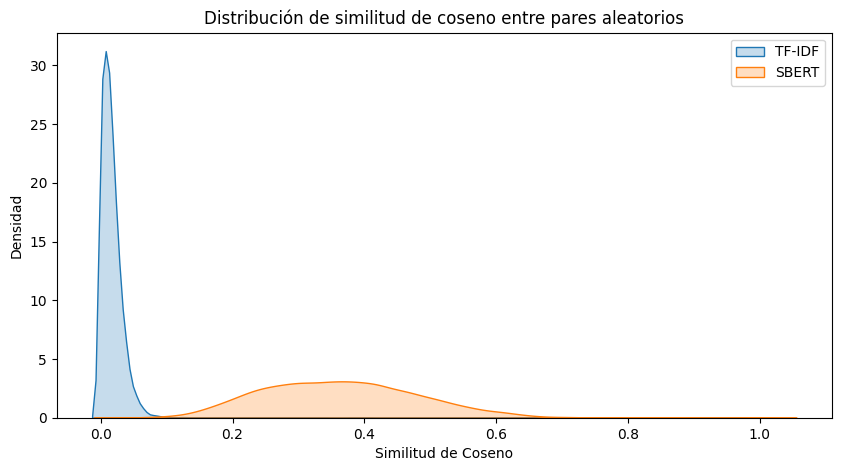

In [ ]:
# Calculamos las matrices completas de similitud
sim_tfidf_matriz = cosine_similarity(matriz_tfidf)
sim_sbert_matriz = cosine_similarity(embeddings_sbert)

# Extraemos solo los pares únicos (triángulo superior sin la diagonal)
indices_pares = np.triu_indices_from(sim_tfidf_matriz, k=1)
distribucion_tfidf = sim_tfidf_matriz[indices_pares]
distribucion_sbert = sim_sbert_matriz[indices_pares]

# Calculamos estadísticas
print("--- ESTADÍSTICAS DE DISTRIBUCIÓN ---")
print(f"TF-IDF -> Media: {distribucion_tfidf.mean():.4f}, Desvío: {distribucion_tfidf.std():.4f}, Rango: [{distribucion_tfidf.min():.4f}, {distribucion_tfidf.max():.4f}]")
print(f"SBERT  -> Media: {distribucion_sbert.mean():.4f}, Desvío: {distribucion_sbert.std():.4f}, Rango: [{distribucion_sbert.min():.4f}, {distribucion_sbert.max():.4f}]")

# Visualización
plt.figure(figsize=(10, 5))
sns.kdeplot(distribucion_tfidf, label="TF-IDF", fill=True)
sns.kdeplot(distribucion_sbert, label="SBERT", fill=True)
plt.title("Distribución de similitud de coseno entre pares aleatorios")
plt.xlabel("Similitud de Coseno")
plt.ylabel("Densidad")
plt.legend()
plt.show()

Como se observa en la curva azul, la distribución presenta un pico agudo y masivo centrado casi exactamente en 0.0. Esto refleja la naturaleza matemática dispersa (sparse) del modelo: al elegir dos libros al azar, la probabilidad de que compartan vocabulario exacto es mínima, por lo que su producto punto es nulo. Esto resulta en una media muy cercana a 0 y un desvío estándar muy pequeño.

La curva naranja muestra una distribución más amplia en forma de campana, con su centro (media) ubicado aproximadamente entre 0.3 y 0.4. Dado que SBERT genera representaciones densas, siempre encontrará un grado base de solapamiento semántico (estructuras gramaticales compartidas, idioma, narrativa general) incluso entre libros de temáticas dispares.

Varianza explicada por PC1: 11.21%
Varianza explicada por PC2: 4.51%
Varianza total conservada: 15.72%
Advertencia: Se descarta casi toda la información original al proyectar a 2D.


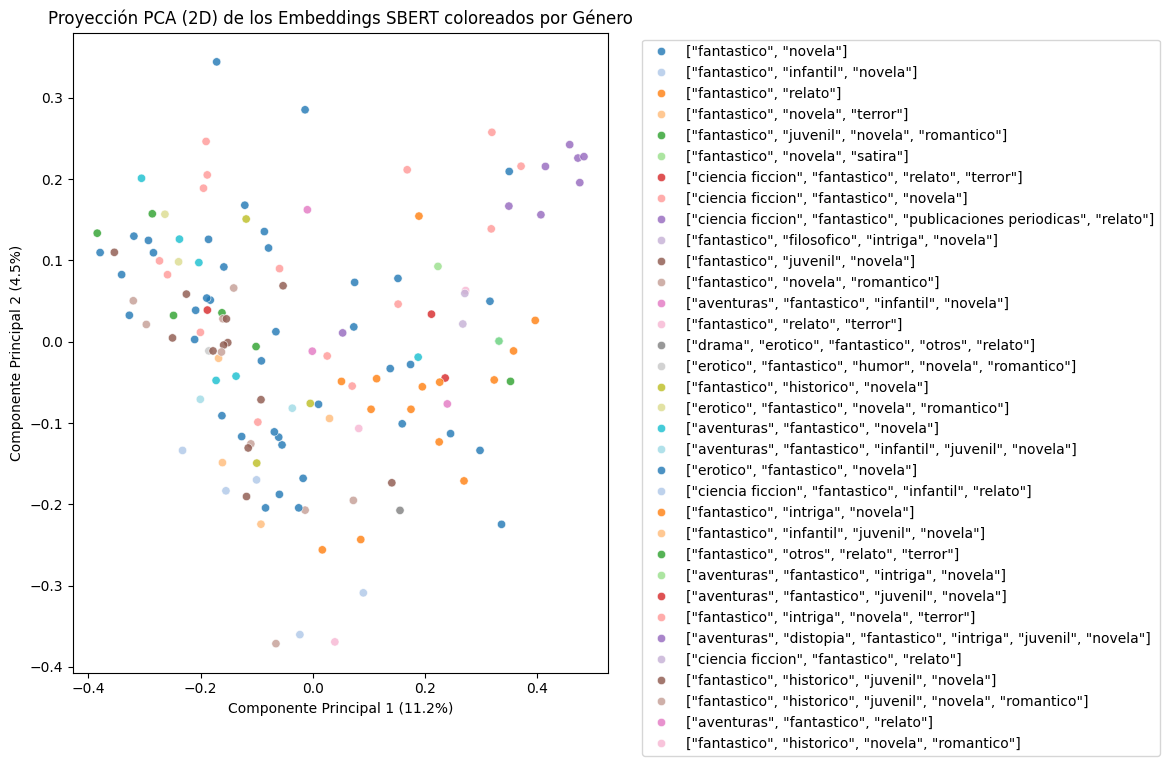

In [ ]:
# Aplicamos PCA para reducir los embeddings de SBERT a 2 dimensiones
pca = PCA(n_components=2)
sbert_pca = pca.fit_transform(embeddings_sbert)

# Obtenemos la varianza explicada para el análisis teórico
var_exp = pca.explained_variance_ratio_
print(f"Varianza explicada por PC1: {var_exp[0]*100:.2f}%")
print(f"Varianza explicada por PC2: {var_exp[1]*100:.2f}%")
print(f"Varianza total conservada: {sum(var_exp)*100:.2f}%")
print("Advertencia: Se descarta casi toda la información original al proyectar a 2D.")

# Preparamos los datos para el gráfico
# Asegúrate de que el nombre de la columna coincida con el de tu metadata (ej. 'genero', 'category', etc.)
columna_genero = 'generos'

plt.figure(figsize=(12, 8))
sns.scatterplot(
    x=sbert_pca[:, 0],
    y=sbert_pca[:, 1],
    hue=metadata[columna_genero],
    palette="tab20",
    alpha=0.8
)
plt.title("Proyección PCA (2D) de los Embeddings SBERT coloreados por Género")
plt.xlabel(f"Componente Principal 1 ({var_exp[0]*100:.1f}%)")
plt.ylabel(f"Componente Principal 2 ({var_exp[1]*100:.1f}%)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

Podemos observar que la proyección 2D por géneros con PCA da tiene una enorme pérdida de información. Observando los ejes podemos ver como la componente primer principal y la segunda solo acumulan un 15,7% de la varianza de la información original. El haber colapsado las 512 dimensiones de los embeddings de SBERT en solo 2 dio lugar a que se descarte más del 84% del contexto. Debido a la alta compresión, los puntos forman una nube solapada donde los colores no presentan fronteras claras ni agrupaciones evidentes. Como advierte la consigna del TP, que los puntos se vean mezclados en este plano bidimensional no significa que el modelo sea incapaz de distinguir géneros, los libros podrían estar perfectamente separados en su plano n-dimensional original.

### 5. Persistencia e indexado

#### 5.1 Funciones

In [ ]:
def normalizar_entrada_multigenero(genero_input):
    """
    Recibe un string con uno o varios géneros separados por comas.
    Devuelve una lista de Python con cada etiqueta normalizada.
    """
    if not isinstance(genero_input, str) or not genero_input.strip():
        return []

    generos_limpios = []
    # Separamos por coma e iteramos
    for g in genero_input.split(','):
        texto = g.strip()
        if texto:
            # Quitamos acentos y pasamos a minúsculas
            normalizado = unicodedata.normalize('NFKD', texto).encode('ASCII', 'ignore').decode('utf-8').lower()
            generos_limpios.append(normalizado)

    return generos_limpios

In [ ]:
class AdaptadorW2V:
    def __init__(self, modelo_w2v, dimension):
        self.modelo_w2v = modelo_w2v
        self.dimension = dimension

    def encode(self, textos):
        # Tokenizamos la consulta
        tokens = textos[0].lower().split()
        # Llamamos a la función de promedio
        vector = calcular_vector_promedio(tokens, self.modelo_w2v.wv, self.dimension)
        # Lo devolvemos como lista de listas
        return [vector]

adaptador_w2v = AdaptadorW2V(modelo_propio, VECTOR_SIZE)

#### 5.2 SBERT - Persistencia e Indexado

In [ ]:
#Establecemos la conexión
conn = psycopg2.connect(DB_URI)
conn.autocommit = True
cursor = conn.cursor()

#Habilitamos la extensión pgvector
cursor.execute("CREATE EXTENSION IF NOT EXISTS vector;")

#Registramos el tipo vector en la conexión actual
register_vector(conn)

# Creamos la tabla
# Cambiamos 'autores' y 'generos' a JSONB para facilitar el filtrado nativo con @>
cursor.execute("""
    DROP TABLE IF EXISTS libros_embeddings;
    CREATE TABLE libros_embeddings (
        id SERIAL PRIMARY KEY,
        titulo TEXT,
        autores JSONB,
        serie TEXT,
        numero_serie REAL,
        generos JSONB,
        embedding VECTOR(512)
    );
""")

# Creamos el índice HNSW para similitud de coseno
cursor.execute("""
    CREATE INDEX ON libros_embeddings USING hnsw (embedding vector_cosine_ops);
""")

# Poblamos la base de datos con toda la metadata
for i, row in metadata.iterrows():
    vector = embeddings_sbert[i]

    # Manejo explícito de vectores nulos o NaN
    if vector is None or np.isnan(vector).any():
        print(f"Advertencia: Vector nulo/NaN detectado en el libro '{row.get('titulo', 'Desconocido')}'. Saltando...")
        continue

    # Normalización del vector (L2 norm)
    norm = np.linalg.norm(vector)
    vector_normalizado = vector / norm if norm > 0 else vector

    # Convertimos los NaNs de Pandas a None (NULL en SQL) para evitar errores de tipo
    titulo = row['titulo'] if pd.notna(row['titulo']) else None
    serie = row['serie'] if pd.notna(row['serie']) else None
    numero_serie = float(row['numero_serie']) if pd.notna(row['numero_serie']) else None

    # Formateo seguro para JSONB: si ya es una lista, la pasamos a string JSON.
    # Si es un string o nulo, lo manejamos correspondientemente.
    autores = row['autores']
    if pd.notna(autores):
        autores = json.dumps(autores) if isinstance(autores, list) else autores
    else:
        autores = None

    generos = row['generos']
    if pd.notna(generos):
        generos = json.dumps(generos) if isinstance(generos, list) else generos
    else:
        generos = None

    # Inserción en Supabase mapeando todas las columnas
    cursor.execute("""
        INSERT INTO libros_embeddings
        (titulo, autores, serie, numero_serie, generos, embedding)
        VALUES (%s, %s, %s, %s, %s, %s)
    """, (
        titulo,
        autores,
        serie,
        numero_serie,
        generos,
        vector_normalizado.tolist()
    ))

#### 5.3 W2V Propio - Persistencia e Indexado

In [ ]:
vectores_documento_w2v = []
for tokens in sinopsis_limpia_tokenizada:
    vector_doc = calcular_vector_promedio(tokens, modelo_propio.wv, 15)
    vectores_documento_w2v.append(vector_doc)

#Crear la segunda tabla en Postgres
cursor.execute("""
    DROP TABLE IF EXISTS libros_embeddings_w2v;
    CREATE TABLE libros_embeddings_w2v (
        id SERIAL PRIMARY KEY,
        titulo TEXT,
        autores JSONB,
        serie TEXT,
        numero_serie REAL,
        generos JSONB,
        embedding VECTOR(15)
    );
""")

#Crear el índice HNSW con la opclass para similitud de coseno
cursor.execute("""
    CREATE INDEX ON libros_embeddings_w2v USING hnsw (embedding vector_cosine_ops);
""")

#Inserción con validación estricta y limpieza de metadata
for i, row in metadata.iterrows():
    vector = np.array(vectores_documento_w2v[i])

    # Manejo explícito de vectores nulos, NaN o infinitos
    if vector is None or np.isnan(vector).any() or not np.isfinite(vector).all():
        print(f"Advertencia: Vector nulo/NaN/Inf detectado en '{row.get('titulo', 'Desconocido')}'. Saltando...")
        continue

    # Normalización del vector (L2 norm)
    norm = np.linalg.norm(vector)
    vector_normalizado = vector / norm if norm > 0 else vector

    titulo = row['titulo'] if pd.notna(row['titulo']) else None
    serie = row['serie'] if pd.notna(row['serie']) else None
    numero_serie = float(row['numero_serie']) if pd.notna(row['numero_serie']) else None

    # Formateo seguro para JSONB
    autores = row['autores']
    if pd.notna(autores):
        autores = json.dumps(autores) if isinstance(autores, list) else autores
    else:
        autores = None

    generos = row['generos']
    if pd.notna(generos):
        generos = json.dumps(generos) if isinstance(generos, list) else generos
    else:
        generos = None

    # Insertar en la base de datos mapeando todas las columnas
    cursor.execute("""
        INSERT INTO libros_embeddings_w2v
        (titulo, autores, serie, numero_serie, generos, embedding)
        VALUES (%s, %s, %s, %s, %s, %s)
    """, (
        titulo,
        autores,
        serie,
        numero_serie,
        generos,
        vector_normalizado.tolist()
    ))

print("Segunda tabla (modelo propio 15D) poblada e indexada correctamente con toda la metadata.")

Segunda tabla (modelo propio 15D) poblada e indexada correctamente con toda la metadata.


#### 5.4 Tablas - Dimensionalidad de los vectores



En PostgreSQL con la extensión pgvector, no es posible que vectores de distintas dimensiones convivan en la misma columna indexada debido a la naturaleza matemática del cálculo de distancias y la estructura del índice HNSW. Matemáticamente, para calcular la similitud de coseno o la distancia euclidiana entre dos vectores, es un requisito estricto que ambos tengan exactamente la misma cantidad de componentes. El producto punto (operación central del coseno) consiste en multiplicar y sumar las coordenadas correspondientes una a una. Si un vector tiene 15 dimensiones y otro 512, la operación matemática queda indefinida.

El índice HNSW (Hierarchical Navigable Small World) preasigna espacio en memoria y construye un grafo espacial asumiendo una geometría fija. Si la columna permitiera dimensiones variables, el motor de base de datos no podría organizar eficientemente los nodos en el espacio multidimensional ni garantizar que las comparaciones durante la búsqueda sean matemáticamente válidas. Por eso, el tipo de dato exige declarar la longitud exacta en su esquema, como VECTOR(512) o VECTOR(15).

#### 5.5 Búsqueda semántica

Esta implementación de la función buscar permite utilizar un filtro por metadata, en este caso género, para limitar el espacio vectorial donde se realizará la búsqueda por similitud de coseno.

Al utilizar el formato JSON, la búsqueda de géneros puede ser multietiqueta, es decir, podemos buscar más de un género a la vez y nos quedaremos con el espacio de embeddings donde alguno o todos los géneros de la consulta coincidan uno a uno en la metadata de los libros en la base de datos.

Ej: Si filtramos por **[ 'Fantasía' , 'Drama' ]**, utilizando el operador `AND` obtendremos libros que posean géneros = **['Fantasía', 'Drama', n_generos_extra ]**, utilizando el operador `OR`, obtendremos todos los libros que posean géneros = **['Fantasía', n_generos]** y también géneros = **['Drama', n_generos]**

Se tienen las siguientes consideraciones:

1) La consulta hecha en lenguaje natural debe ser vectorizada y normalizada por el modelo correspondiente, y debe consultar su respectiva tabla.

2) Los géneros utilizados como filtros serán normalizados, pasando todas las etiquetas a minúscula y eliminando los caracteres especiales para asegurarnos el match directo a la hora de filtrar.

3) La búsqueda semántica está dada por el operador `<=>` que corresponde al operador de similitud de coseno, que medirá la distancia espacial entre el vector consulta y los embeddings de libros filtrados, o no, por género.

In [ ]:
def buscar(consulta, k=5, filtro_generos=None, operador_logico="OR", tabla="libros_embeddings", modelo=modelo_sbert, oversample_k=50):
    """
    Resuelve la búsqueda por similitud en SQL utilizando post-filtrado con sobre-muestreo (CTE)
    para evitar el problema de recall con índices HNSW.
    """
    # Vectorizamos y normalizamos la consulta
    vector_consulta = modelo.encode([consulta])[0]
    norm = np.linalg.norm(vector_consulta)
    vector_norm = vector_consulta / norm if norm > 0 else vector_consulta
    vector_list = vector_norm.tolist()

    # Armamos la consulta dinámica
    if filtro_generos:
        generos_lista = normalizar_entrada_multigenero(filtro_generos)

        if operador_logico.upper() == "AND":
            filtro_parametro = json.dumps(generos_lista)
            clausula_where = "WHERE generos @> %s::jsonb"
        else:
            filtro_parametro = generos_lista
            clausula_where = "WHERE generos ?| %s::text[]"

        # Utilizamos una CTE (WITH) para el post-filtrado puramente en SQL
        sql = f"""
            WITH top_candidatos AS (
                SELECT titulo, generos, (embedding <=> %s::vector) AS distancia
                FROM {tabla}
                ORDER BY embedding <=> %s::vector
                LIMIT %s
            )
            SELECT titulo, 1 - distancia AS similitud, generos
            FROM top_candidatos
            {clausula_where}
            ORDER BY distancia ASC
            LIMIT %s;
        """
        # Parámetros: 2 vectores para el WITH, oversample_k, el filtro JSON/Array, y el k final
        parametros = (vector_list, vector_list, oversample_k, filtro_parametro, k)

    else:
        # Búsqueda normal sin filtros
        sql = f"""
            SELECT titulo, 1 - (embedding <=> %s::vector) AS similitud, generos
            FROM {tabla}
            ORDER BY embedding <=> %s::vector
            LIMIT %s;
        """
        parametros = (vector_list, vector_list, k)

    # Ejecutamos
    cursor.execute(sql, parametros)
    return cursor.fetchall()

Observamos ejemplos básicos de como utilizar la función buscar con SBERT

In [ ]:
print("--- SBERT | Operador: OR  ---")
res_sbert_or = buscar(
    consulta="un grupo de amigos explorando reinos mágicos y criaturas perdidas",
    k=3,
    filtro_generos="Fantástico",
    operador_logico="OR",
    tabla="libros_embeddings",
    modelo=modelo_sbert
)

for r in res_sbert_or:
    print(f"{r[0]} (Similitud: {r[1]:.3f}) - Géneros: {r[2]}")

print("\n--- SBERT | Operador: AND ---")
res_sbert_and = buscar(
    consulta="el conflicto interno de una tripulación perdida en el espacio profundo",
    k=3,
    filtro_generos="Ciencia Ficción, Novela",
    operador_logico="AND",
    tabla="libros_embeddings",
    modelo=modelo_sbert
)
for r in res_sbert_and:
    print(f"{r[0]} (Similitud: {r[1]:.3f}) - Géneros: {r[2]}")

--- SBERT | Operador: OR  ---
Alquimia y fuego (Similitud: 0.361) - Géneros: ['fantastico', 'juvenil', 'novela']
Skandar y los Juegos del Caos (Similitud: 0.355) - Géneros: ['fantastico', 'juvenil', 'novela']
Una ventana a la oscuridad (Similitud: 0.348) - Géneros: ['fantastico', 'novela', 'romantico']

--- SBERT | Operador: AND ---
La tierra fragmentada (Similitud: 0.240) - Géneros: ['ciencia ficcion', 'fantastico', 'novela']
La última luz de Traila (Similitud: 0.225) - Géneros: ['ciencia ficcion', 'fantastico', 'novela']
Escuadrón: La saga (Similitud: 0.222) - Géneros: ['ciencia ficcion', 'fantastico', 'novela']


Observamos ejemplos básicos de como utilizar la función buscar con Word2Vec

In [ ]:
print("\n--- Word2Vec (15D) | Operador: OR  ---")

res_w2v_or = buscar(
    consulta="un grupo de amigos explorando reinos mágicos y criaturas perdidas",
    k=3,
    filtro_generos="Fantástico",
    operador_logico="OR",
    tabla="libros_embeddings_w2v",
    modelo=adaptador_w2v
)
for r in res_w2v_or:
    print(f"{r[0]} (Similitud: {r[1]:.3f}) - Géneros: {r[2]}")

print("\n--- Word2Vec (15D) | Operador: AND ---")

res_w2v_and = buscar(
    consulta="el conflicto interno de una tripulación perdida en el espacio profundo",
    k=3,
    filtro_generos="Ciencia Ficción, Novela",
    operador_logico="AND",
    tabla="libros_embeddings_w2v",
    modelo=adaptador_w2v
)
for r in res_w2v_and:
    print(f"{r[0]} (Similitud: {r[1]:.3f}) - Géneros: {r[2]}")


--- Word2Vec (15D) | Operador: OR  ---
Alfa (Similitud: 0.969) - Géneros: ['erotico', 'fantastico', 'humor', 'novela', 'romantico']
El canto antiguo (Similitud: 0.964) - Géneros: ['erotico', 'fantastico', 'novela']
Serafina y la capa negra (Similitud: 0.963) - Géneros: ['fantastico', 'infantil', 'juvenil', 'novela']

--- Word2Vec (15D) | Operador: AND ---
Carl el Mazmorrero (Similitud: 0.933) - Géneros: ['ciencia ficcion', 'fantastico', 'novela']
Convergencia (Similitud: 0.916) - Géneros: ['ciencia ficcion', 'fantastico', 'novela']
Cataclismo (Similitud: 0.901) - Géneros: ['ciencia ficcion', 'fantastico', 'novela']


Hay que tener en cuenta que al combinar búsquedas vectoriales sobre índices aproximados como HNSW con filtros por metadata, debemos realizar un post-filtrado por género. El algoritmo HNSW optimiza la búsqueda navegando a través de un grafo espacial, utilizando los nodos más cercanos a la consulta como conectores para seguir explorando.

Si aplicamos un filtro duro al mismo tiempo que la búsqueda vectorial, el algoritmo descarta los nodos vecinos que son espacialmente cercanos pero que no cumplen con la condición del género. Al rechazar estos nodos, el índice se queda sin caminos para continuar la exploración, estancándose en un mínimo local. Esto provoca una caída del recall y el sistema puede devolver menos de k resultados o resultados irrelevantes, a pesar de que los embeddings de los libros existan en la base de datos pero se encuentren inaccesibles por el pre-filtrado.

Es por eso que implementamos un post-filtrado con sobre-muestreo (oversample_k = 50), dejamos que el índice busque libremente los 50 vecinos más similares, y luego aplicamos el filtro de metadata.



### 6. Evaluación de los modelos

#### 6.1 Funciones auxiliares para la evaluación

In [ ]:
def recuperar_titulos_top_k(vector_query, matriz_docs, titulos, k=5):
    """Retorna una lista plana con los top K títulos más similares."""
    similitudes = cosine_similarity([vector_query], matriz_docs)[0]
    indices_top = similitudes.argsort()[-k:][::-1]
    return titulos.iloc[indices_top].tolist()

def limpiar_titulo(t):
    """Normaliza títulos - elimina caracteres especiales, acentos y pasa todo a minúsculas"""
    texto = str(t).strip().lower()
    texto_plano = unicodedata.normalize('NFKD', texto).encode('ASCII', 'ignore').decode('utf-8')
    return texto_plano

def precision_at_k(relevantes, recuperados, k=5):
    """Calcula la proporción de resultados relevantes para la consulta en los primeros k resultados obtenidos"""
    top_k = recuperados[:k]

    # Limpiamos
    relevantes_limpios = [limpiar_titulo(t) for t in relevantes]
    top_k_limpios = [limpiar_titulo(t) for t in top_k]

    # Intersección
    aciertos = set(relevantes_limpios).intersection(set(top_k_limpios))

    return len(aciertos) / k

#### 6.2 Evaluación

Para evaluar el desempeño de los modelos, implementamos la métrica Precision@K con K=5. Esta medida nos permite cuantificar qué proporción de los primeros cinco documentos recuperados por el buscador son verdaderamente relevantes para cada consulta de nuestro conjunto de prueba.

In [ ]:
# Cargar las consultas
with open('queries.json', 'r', encoding='utf-8') as f:
    eval_queries = json.load(f)

In [ ]:
# Muestra el objeto JSON en un visor colapsable
display(JSON(eval_queries))

<IPython.core.display.JSON object>

In [ ]:
K = 5
N_corpus = len(metadata)

resultados = {
    "TF-IDF": [],
    "Word2Vec": [],
    "SBERT": [],
    "Azar": []
}

# Convertir la lista de Word2Vec a una matriz para usar cosine_similarity
matriz_w2v = np.array(vectores_documento_w2v)

for item in eval_queries:
    query = item["query"]
    relevantes = item["relevant_titles"]

    #Piso de Azar
    precision_azar_esperada = len(relevantes) / N_corpus
    resultados["Azar"].append(precision_azar_esperada)

    #Evaluación TF-IDF
    query_limpia = limpiar_texto_tfidf(query)
    vec_tfidf = vectorizer.transform([query_limpia]).toarray()[0]
    recuperados_tfidf = recuperar_titulos_top_k(vec_tfidf, matriz_tfidf, metadata['titulo'], k=K)
    resultados["TF-IDF"].append(precision_at_k(relevantes, recuperados_tfidf, K))

    #Evaluación Word2Vec
    query_tokenizada = tokenizar_texto(query_limpia)
    vec_w2v = calcular_vector_promedio(query_tokenizada, modelo_propio.wv, VECTOR_SIZE)
    recuperados_w2v = recuperar_titulos_top_k(vec_w2v, matriz_w2v, metadata['titulo'], k=K)
    resultados["Word2Vec"].append(precision_at_k(relevantes, recuperados_w2v, K))

    #Evaluación SBERT
    vec_sbert = modelo_sbert.encode([query])[0]
    recuperados_sbert = recuperar_titulos_top_k(vec_sbert, embeddings_sbert, metadata['titulo'], k=K)
    resultados["SBERT"].append(precision_at_k(relevantes, recuperados_sbert, K))

# Agregar y reportar las métricas promedio finales
print(f"--- RESULTADOS FINALES: PRECISION@{K} PROMEDIO ---")
for modelo, scores in resultados.items():
    promedio = sum(scores) / len(scores)
    print(f"{modelo:<10} | {promedio:.4f}")

--- RESULTADOS FINALES: PRECISION@5 PROMEDIO ---
TF-IDF     | 0.1800
Word2Vec   | 0.0800
SBERT      | 0.1600
Azar       | 0.0070


Podemos observar que nuestras métricas promedio son bajas sin importar el modelo.

SBERT presenta una cantidad de aciertos mayor, lo que se traduce en una métrica superior al resto. Esto se debe a que puede captar el significado de la consulta,sinónimos y conceptos más abstractos, lo que le permite encontrar similitudes donde un modelo basado puramente en el léxico, fallaría.

TF-IDF presenta una cantidad de aciertos menor que SBERT pero mayor que Word2Vec. Esto se debe a que dentro de la consulta, se deben utilizar estrictamente las palabras que se encuentran dentro del vocabulario para poder encontrar coincidencias. Es útil para una búsqueda por términos clave pero falla si se utilizan sinónimos, o frases complejas ya que no capta significado semántico. Hay que tener en cuenta, a la hora de realizar consultas, que el preprocesamiento eliminará stopwords y normalizará el texto, favoreciendo estas palabras clave. Si realizamos una consulta llena de stopwords y sin palabras clave, tenderá a fallar.

Word2Vec logra captar un mínimo de relaciones semánticas, esto se debe a la calidad del corpus mismo, no solamente son pocos ejemplares, si no que también tenemos una escasa cantidad de palabras en nuestro vocabulario. Esto nos obliga a utilizar una dimensión de vector de salida pequeño, con una ventana acotada dentro del promedio de tokens por sinopsis.  Además, el promediado de vectores elimina todo sentido de orden, no pondera palabras clave y no resuelve el problema de la polisemia, lo que resulta en una pérdida de peso semántico significativa.

En tanto al azar, tenemos un puntaje muy cercano a cero. Esto nos indica que el corpus es lo suficientemente grande, lo que no nos permite acertar por casualidad ya que es estadísticamente improbable. A su vez, los tres modelos planteados superan el umbral del azar, lo que nos dá a entender que se produjo algún tipo de aprendizaje, por más limitado que sea, por parte de los modelos Word2Vec y SBERT.

In [ ]:
# Creamos un DataFrame con los resultados que obtuvimos en la celda anterior
df_detalles = pd.DataFrame(resultados)

# Le agregamos la columna con el texto de la consulta al principio
df_detalles.insert(0, "Consulta", [item["query"] for item in eval_queries])
df_detalles

,Consulta,TF-IDF,Word2Vec,SBERT,Azar
0,"Elantris, la poderosa y bella capital de Arelo...",0.2,0.2,0.2,0.006993
1,Han pasado siglos desde la caída de las diez ó...,0.2,0.0,0.2,0.006993
2,Y aunque la ciencia y tecnología juega un pape...,0.2,0.0,0.2,0.006993
3,¿Sabes qué es peor que romper con tu novia? Te...,0.2,0.2,0.2,0.006993
4,Entre campos de batalla llenos de fantasmas y ...,0.2,0.0,0.2,0.006993
5,Hace muchos años las cuatro naciones vivian en...,0.0,0.0,0.0,0.006993
6,"Shai, una maga Falsificadora, ha sido condenad...",0.2,0.0,0.2,0.006993
7,La historia nos cuenta el viaje fantástico de ...,0.2,0.2,0.2,0.006993
8,"Los niños de Oxford están desapareciendo, y se...",0.2,0.2,0.2,0.006993
9,"Roland Deschain, el último pistolero de Mundo ...",0.2,0.0,0.0,0.006993


La consulta 5 es de esperar que falle, los valores de precision son 0 con todos los modelos, ya que es la consulta que se diseñó para no compartir ninguna palabra con el documento relevante.

Diferente es el caso de la consulta 9, en donde tanto Word2Vec como SBERT fallan. Creemos que esto se puede deber a que, por un lado, como Word2Vec trabaja a nivel de palabra para la frase dada, promedia los embeddings de cada término, por lo que palabras como 'Deschain' estarán fuera del vocabulario y, al promediarse con los demás términos, se pierde especificidad y se obtiene un vector con ruido.

Para SBERT, el problema podría deberse a que, si bien puede trabajar con oraciones, la query contiene un fragmento truncado de la sinopsis completa. De modo que, cuando las compara, la información sobre el autor, la mezcla de géneros y los múltiples aspectos sobre el mundo en el que se ambienta la obra hacen que los significados globales de ambos vectores distan bastante entre sí.

Es por esto que TF-IDF no falló: aunque tuvo solo un fragmento de la sinopsis, al basarse en la frecuencia de aparición es muy bueno para encontrar coincidencias literales, y palabras poco frecuentes como 'Deschain' otorgan un valor de IDF muy alto, haciendo que la búsqueda sea exitosa.


#### 6.3 Conclusión

En base al análisis de las métricas y el comportamiento de cada arquitectura, concluimos que la elección del modelo final se derivará al uso que se quiera dar a la aplicación en producción.

Recomendamos usar TF-IDF si se requieren búsquedas exactas por palabras clave, imaginamos un sistema de consultas predefinidas, parametrizadas, o filtros por etiquetas. Más aún si el usuario conoce el vocabulario del corpus y busca términos literales o nombres propios. Puede ser util en sistemas que requieran costos computacionales bajos ya que el consumo es mínimo.

Si lo que se requiere es un sistema de recomendación de libros donde el usuario deba utilizar lenguaje natural para obtener resultados, optaríamos por SBERT.
El usuario sería capaz de describir el tema que quiere buscar, puede definir conceptos abstractos sin recaer en la exactitud del léxico utilizado y aún así obtener resultados de calidad.

En caso de querer obtener una mejora en métricas, sería necesario utilizar un corpus mucho más grande, dicho uso dependerá de las limitaciones computacionales del entorno donde se haga el entrenamiento.

## 7. Funcionalidad Avanzada

Para la funcionalidad avanzada, aprovechando que nuestro proceso de scraping inicial extrajo más información que la necesaria, vamos a realizar un recomendador de libros similares basándonos en un libro elegido por el usuario.

Para mejorar la experiencia del usuario, una vez ingresado el libro para buscar recomendaciones, se renderizarán en formato de cards las portadas de los libros, junto con su titulo, autor y métrica de similitud. Estas cards son clickeables y redirigen a la URL de Lectulandia donde podrán descargar el libro seleccionado.

Si se hubiese hecho un scraping de los links de descarga, podríamos haber ofrecido la funcionalidad de descarga desde este collab. Esto podría infligir en las políticas de privacidad de Lectulandia, por lo que no se agregará directamente.

In [ ]:
def obtener_recomendaciones_visuales(titulo_origen, metadata, matriz_embeddings, top_k=6):
    """Obtiene los top_k libros similares (excluyendo la saga) con sus URLs e imágenes."""
    filtro = metadata[metadata['titulo'] == titulo_origen]

    if filtro.empty:
        print("Libro no encontrado en la base.")
        return []

    idx_origen = filtro.index[0]
    serie_origen = metadata.loc[idx_origen, 'serie']
    vector_origen = matriz_embeddings[idx_origen]

    similitudes = cosine_similarity([vector_origen], matriz_embeddings)[0]
    indices_top = similitudes.argsort()[::-1]

    resultados = []

    for idx in indices_top:
        if idx == idx_origen:
            continue

        serie_candidato = metadata.loc[idx, 'serie']
        if pd.notna(serie_origen) and pd.notna(serie_candidato) and serie_origen == serie_candidato:
            continue

        resultados.append({
            'titulo': metadata.loc[idx, 'titulo'],
            'autores': metadata.loc[idx, 'autores'],
            'similitud': similitudes[idx],
            'url_libro': metadata.loc[idx, 'url_libro'],
            'portada_url': metadata.loc[idx, 'portada_url']
        })

        if len(resultados) == top_k:
            break

    return resultados

def renderizar_grid(recomendaciones):
    """Toma la lista de recomendaciones y genera un HTML con un grid de 3x2."""
    if not recomendaciones:
        return

    # CSS para armar el grid de 3 columnas
    estilos_css = """
    <style>
        .grid-container {
            display: grid;
            grid-template-columns: repeat(3, 1fr);
            gap: 20px;
            padding: 10px;
        }
        .book-card {
            border: 1px solid #e0e0e0;
            border-radius: 8px;
            padding: 15px;
            text-align: center;
            background-color: #f9f9f9;
            box-shadow: 2px 2px 8px rgba(0,0,0,0.1);
            transition: transform 0.2s;
        }
        .book-card:hover {
            transform: scale(1.03);
            box-shadow: 3px 3px 12px rgba(0,0,0,0.2);
        }
        .book-cover {
            height: 220px;
            object-fit: cover;
            border-radius: 4px;
            cursor: pointer;
        }
        .book-title {
            font-size: 14px;
            font-weight: bold;
            margin: 10px 0 5px 0;
            color: #333;
        }
        .book-author {
            font-size: 12px;
            color: #666;
            margin-bottom: 8px;
        }
        .book-sim {
            font-size: 13px;
            color: #2e7d32; /* Verde para destacar el score */
            font-weight: bold;
        }
        a { text-decoration: none; }
    </style>
    """

    # Armado dinámico de las tarjetas HTML
    tarjetas_html = ""
    for rec in recomendaciones:
        # Limpiamos el string del autor por si viene como ["Autor"]
        autor_limpio = str(rec['autores']).replace('["', '').replace('"]', '').replace("['", "").replace("']", "").strip().title()

        tarjeta = f"""
        <div class="book-card">
            <a href="{rec['url_libro']}" target="_blank">
                <img class="book-cover" src="{rec['portada_url']}" alt="Portada de {rec['titulo']}">
            </a>
            <div class="book-title">{rec['titulo']}</div>
            <div class="book-author">{autor_limpio}</div>
            <div class="book-sim">Similitud: {rec['similitud']:.3f}</div>
        </div>
        """
        tarjetas_html += tarjeta

    # Ensamblamos todo
    html_final = f"{estilos_css}<div class='grid-container'>{tarjetas_html}</div>"

    # Mostramos el HTML en el notebook
    display(HTML(html_final))


In [ ]:
recs = obtener_recomendaciones_visuales("Las flores en llamas", metadata, embeddings_sbert)
renderizar_grid(recs)

In [ ]:
recs =obtener_recomendaciones_visuales("El Archivo de las Tormentas 1-5", metadata, embeddings_sbert)
renderizar_grid(recs)